# Sentiment Intelligence on Citizen Complaints (PQR)

Public service providers in Colombia must operate a formal feedback channel called **PQR: Peticiones, Quejas y Reclamos** (petitions, complaints and claims). Every record carries a free text narrative written by a citizen, plus operational metadata: what kind of request it is, where it comes from, when it was received and when it was closed.

This study takes 307 real PQR records filed between 2017 and 2021 during a large sewer and aqueduct construction program in three municipalities of the AburrÃ¡ Valley (Bello, Copacabana and Girardota) and answers three questions:

1. **What do citizens feel** when they write to the program: how negative is the channel, and which emotions dominate?
2. **Where and when** is negativity concentrated: which municipality, watershed, entry route and period carry the most negative narratives?
3. **Does feeling relate to operations**: do angrier records take longer to close, and are they more often the operator's responsibility?

The scoring engine is a Spanish transformer (BERT family) fine tuned for sentiment, cross checked with an independent multilingual model, and extended with an emotion classifier.

**Data ethics**: the published dataset was anonymized with a rule based masking engine before analysis. Personal names, national identity numbers, phone numbers, street addresses, vehicle plates, equipment serials and every corporate identity were replaced with typed placeholders such as `[NOMBRE]` or `[EMPRESA]`. The provider behind the program is intentionally not disclosed. The complaint narratives remain in their original Spanish, since that is the language the models score.


## 1. Setup

All logic lives in the `pqr_sentiment` package (installable from this repository with `pip install -e .`). The notebook is a thin, readable consumer: loading, cleaning, scoring, statistics and every chart come from tested package functions.

In [1]:
from pathlib import Path

import pandas as pd

from pqr_sentiment import config
from pqr_sentiment.data import load_records, clean_records, parse_flexible_dates
from pqr_sentiment.sentiment import (
    ml_available, score_records, save_scored, load_scored,
)
from pqr_sentiment import plots, stats, text_mining

theme = plots.apply_theme(dark=False)
pd.set_option("display.max_colwidth", 90)

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
DATA = REPO_ROOT / "data"
FIGURES = REPO_ROOT / "reports" / "figures"

import matplotlib, sklearn, scipy
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

pandas 2.3.3 | matplotlib 3.10.8 | scikit-learn 1.7.2 | scipy 1.15.3


## 2. Data loading and validation

`load_records` validates the schema before returning anything: a missing column fails fast with a clear error instead of surfacing as a confusing `KeyError` five cells later.

| Column | Meaning |
| :-- | :-- |
| `record_id` | Consecutive identifier from the source system |
| `pqr_type` | Petition, complaint or claim |
| `received_date`, `due_date`, `attended_date`, `closed_date` | Lifecycle dates: reception, regulatory deadline, first attention, closure |
| `entry_route` | Who received the record: contractor, supervision firm or the utility company |
| `watershed`, `municipality`, `neighborhood` | Where the work that triggered the record happens |
| `description` | The citizen narrative, in Spanish, anonymized with typed placeholders |
| `attributable` | Whether the operator accepted responsibility |
| `status` | Open or closed |


In [2]:
raw = load_records(DATA / config.PUBLIC_DATASET_NAME)
print(f"{raw.shape[0]} records, {raw.shape[1]} columns")
raw[["record_id", "pqr_type", "received_date", "entry_route", "municipality", "description"]].head(4)

307 records, 13 columns


,record_id,pqr_type,received_date,entry_route,municipality,description
0,1,Petición,2017-10-20 00:00:00,Interventoría,Copacabana,Usuaria contacta al personal de interventoría para exponer tema de acometida de alcant...
1,2,Queja,2017-10-24 00:00:00,Contratista,Copacabana,"Durante trabajos de reposición de alcantarillado en la dirección del asunto, el día 20..."
2,3,Petición,2017-10-24 00:00:00,Contratista,Copacabana,Usuario se comunica telefónicamente a la línea de atención del contratista para solici...
3,4,Queja,2017-11-02 00:00:00,Interventoría,Girardota,Usuario reporta que con el material particulado de las obras se afectó fotocopiadora y...


## 3. Cleaning: every defect found, fixed and accounted for

Operational exports are never clean, and this one is honest about it. The raw file carries five families of defects, all preserved exactly as the source system produced them:

1. **Stray whitespace** that splits categories: `"Queja "` with a trailing space is counted apart from `"Queja"`.
2. **Free case labels**: the responsibility flag arrives in six spellings, from `"Imputable"` to `"NO Imputable"`.
3. **Neighborhood spelling variants**: the same place typed twice with different capitalization.
4. **Mixed date encodings**: ISO timestamps, day first strings, Excel serial numbers, and strings with stray quotes.
5. **Unrecoverable values**: impossible dates like `31/02/2019`, a year truncated to `201`, and free text where a date should be.

Two raw examples before cleaning:

In [3]:
print("pqr_type raw value counts (note the trailing space variant):")
print(raw["pqr_type"].value_counts().to_string())
print()
print("attributable raw value counts:")
print(raw["attributable"].value_counts().to_string())

pqr_type raw value counts (note the trailing space variant):
pqr_type
Queja       192
Reclamo      63
Petición     38
Queja        14

attributable raw value counts:
attributable
Imputable        216
No imputable      76
No Imputable       7
no imputable       3
Compartida         2
NO Imputable       1
No imputable       1
no Imputable       1


In [4]:
print("date values no parser should invent an answer for:")
for column in ["received_date", "due_date", "closed_date"]:
    parsed = parse_flexible_dates(raw[column])
    broken = raw.loc[raw[column].notna() & (raw[column].astype(str).str.len() > 0) & parsed.isna(), column]
    for value in broken:
        print(f"  {column}: {value!r}")

date values no parser should invent an answer for:
  received_date: '06/05/201'
  due_date: '29/0/2018'
  due_date: '31/02/2019'
  due_date: '11/05/201'
  closed_date: 'Cerrada por [EMPRESA]'
  closed_date: '27/11/201/8'
  closed_date: '105/09/2020'


`clean_records` normalizes whitespace, maps every categorical value to a stable English code, merges neighborhood case variants into their most frequent spelling, parses all four date columns, derives `resolution_days`, `sla_met` and `received_month`, and drops the rows that cannot be analyzed. Nothing disappears silently: the report below accounts for every cell it touched.

In [5]:
records, report = clean_records(raw)
report.to_frame()

,metric,value
0,rows_in,307
1,rows_out,306
2,rows_dropped,1
3,neighborhood_variants_merged,5
4,rows_dropped_missing_essentials,1
5,unparseable_date_values,8
6,whitespace_trimmed_cells,266


In [6]:
report.dropped[["record_id", "received_date", "drop_reason"]]

,record_id,received_date,drop_reason
301,304,NaT,missing received_date


One record is dropped: its reception date arrived as `06/05/201`, a year truncated at the source. Guessing between 2016 and 2019 would contaminate the time analysis, so the honest move is exclusion. The working set is **306 records**.

## 4. The shape of the channel

Volumes first: what arrives, from where, and through which door.

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/records_by_type.png')

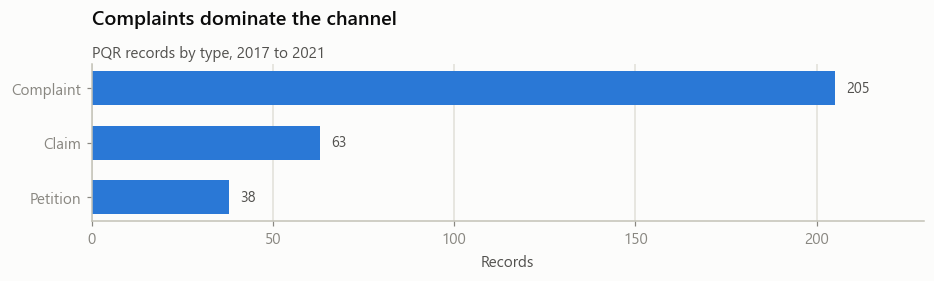

In [7]:
fig = plots.volume_by_category(
    records, "pqr_type", "Complaints dominate the channel",
    subtitle="PQR records by type, 2017 to 2021",
    display=config.VALUE_DISPLAY,
)
plots.save_figure(fig, "records_by_type", FIGURES)

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/records_by_municipality.png')

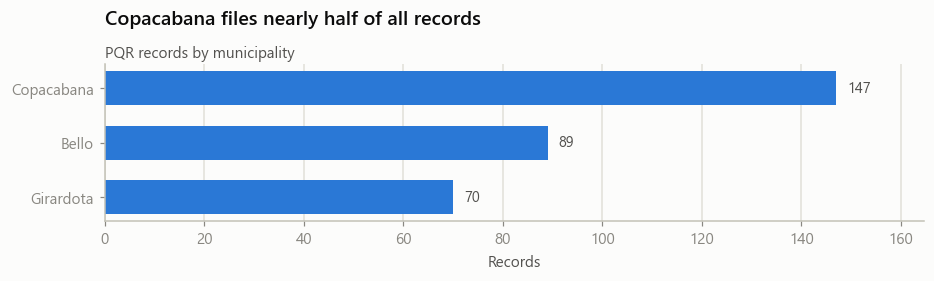

In [8]:
fig = plots.volume_by_category(
    records, "municipality", "Copacabana files nearly half of all records",
    subtitle="PQR records by municipality",
)
plots.save_figure(fig, "records_by_municipality", FIGURES)

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/records_by_entry_route.png')

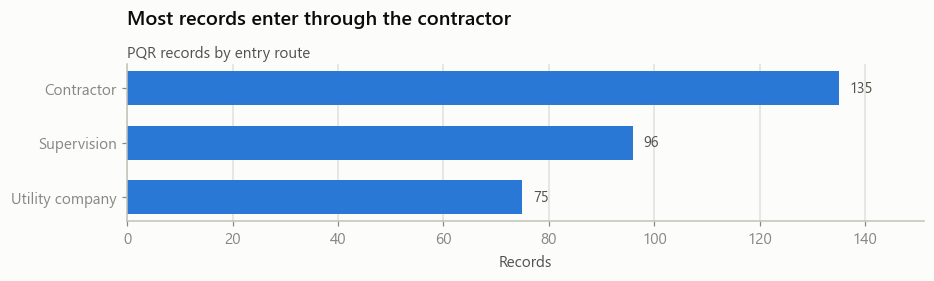

In [9]:
fig = plots.volume_by_category(
    records, "entry_route", "Most records enter through the contractor",
    subtitle="PQR records by entry route",
    display=config.VALUE_DISPLAY,
)
plots.save_figure(fig, "records_by_entry_route", FIGURES)

In [10]:
length = text_mining.text_length_stats(records, "description")
length.round(1)

,min,median,mean,max
unit,,,,
characters,42,261.0,304.3,1270
words,7,43.0,50.4,223


The narratives are substantial: a median of about 260 characters, with the longest above 1,200. These are not star ratings, they are paragraphs written by affected residents, which is exactly the kind of input a transformer reads well and a keyword rule reads poorly.

## 5. Sentiment scoring with a Spanish transformer

The primary scorer is **robertuito** (`pysentimiento/robertuito-sentiment-analysis`), a RoBERTa model pretrained on half a billion Spanish tweets and fine tuned for sentiment on the TASS corpora. It returns a label (`NEG`, `NEU`, `POS`) plus the full probability distribution, so every downstream chart can distinguish a confident negative from a borderline one.

The cell below runs live inference when the ML stack is installed, and falls back to the cached scores committed with the repository otherwise, so the notebook reproduces end to end on any machine.

In [11]:
RUN_INFERENCE = True

scored_path = DATA / config.SCORED_DATASET_NAME
scored = None
if not (RUN_INFERENCE and ml_available()):
    scored = load_scored(scored_path)
    if scored is not None:
        print(f"loaded cached scores: {scored_path.name}")

if scored is None:
    def progress(done, total):
        if done % 100 == 0 or done == total:
            print(f"  scored {done}/{total}")
    scored = score_records(records, progress=progress)
    save_scored(scored, scored_path)
    print(f"cache written: {scored_path.name}")

  scored 100/306


  scored 200/306


  scored 300/306


  scored 306/306


  scored 100/306


  scored 200/306


... (2 outputs left out)

  scored 100/306


  scored 200/306


  scored 300/306


  scored 306/306
cache written: pqr_scored.csv


In [12]:
counts = scored["sentiment"].value_counts().reindex(config.SENTIMENT_ORDER, fill_value=0)
shares = (counts / counts.sum() * 100).round(1)
pd.DataFrame({"records": counts, "share_%": shares})

,records,share_%
sentiment,,
NEG,207,67.6
NEU,99,32.4
POS,0,0.0


Two out of three narratives are negative, and **not a single record is scored positive**. That is the honest baseline of a works program complaint channel: people write when something bothers them. It also means the interesting questions are not "how positive are we" but "how intense is the negativity, where does it concentrate, and what separates a neutral request from an angry claim".

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/model_confidence.png')

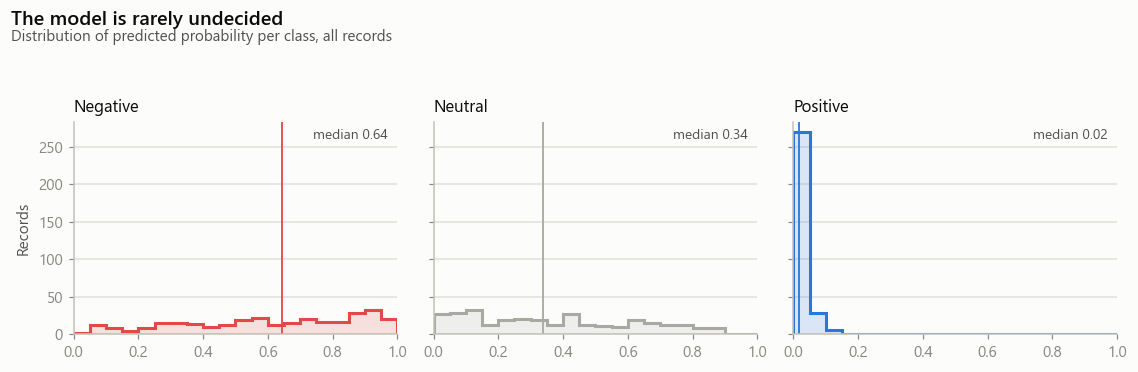

In [13]:
fig = plots.probability_distributions(
    scored, "The model is rarely undecided",
    subtitle="Distribution of predicted probability per class, all records",
)
plots.save_figure(fig, "model_confidence", FIGURES)

In [14]:
def show_examples(frame, label, n=2):
    subset = frame[frame["sentiment"] == label].nlargest(n, f"prob_{label.lower()}")
    for _, row in subset.iterrows():
        print(f"[{label} p={row[f'prob_{label.lower()}']:.2f}] {row['description'][:260]}")
        print()

show_examples(scored, "NEG")
show_examples(scored, "NEU")

[NEG p=0.98] La usuaria manifiesta la siguientes inconformidades: -El ruido de la concertadora es algo que no soporta - Con la maquinaria se averió la Puerta Garaje del parqueadero. Los vehículos amanecen parqueados y obstruyen el parqueadero. - La tapa de registro de la v

[NEG p=0.98] Usuario inconforme con los trabajos que se están realizando por el sector, por parte de ingeniería y contratos sobre modernización en la red de alcantarillado ya que las medidas que están tomando no son las más adecuadas y están afectando y perjudicando a la c

[NEU p=0.90] El día 16 de abril de 2021 se acercó el [NOMBRE] de la JAC del Paraíso indagando requiriendo una visita al lugar de intervención de obra en el botadero 2 con el fin de revisar posibles afectaciones por los trabajos realizados. Se concerta cita telefónica con e

[NEU p=0.90] Las usuaria solicita que los dos apartamentos sean conectados a la red principal ubicada en [DIRECCION] (101, 102)



## 6. Second opinion: does an independent model agree?

Any single model can be confidently wrong, so the labels are cross checked against `nlptown/bert-base-multilingual-uncased-sentiment`, an independent multilingual model trained on product reviews that grades text from 1 to 5 stars. Stars 1 and 2 map to negative, 3 to neutral, 4 and 5 to positive. The two models share no training data, no architecture lineage and no label space.

star grades: {1: 257, 2: 26, 3: 14, 4: 9}
raw agreement: 68.6%
Cohen kappa:   0.13


WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/model_agreement.png')

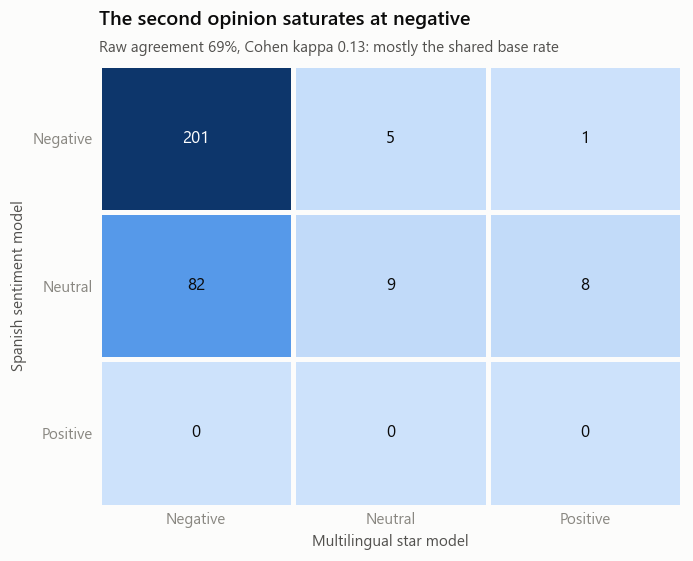

In [15]:
from sklearn.metrics import cohen_kappa_score

print("star grades:", scored["stars"].value_counts().sort_index().to_dict())
kappa = cohen_kappa_score(scored["sentiment"], scored["stars_sentiment"])
agreement = (scored["sentiment"] == scored["stars_sentiment"]).mean()
print(f"raw agreement: {agreement:.1%}")
print(f"Cohen kappa:   {kappa:.2f}")

fig = plots.agreement_heatmap(
    scored, "The second opinion saturates at negative",
    subtitle=f"Raw agreement {agreement:.0%}, Cohen kappa {kappa:.2f}: mostly the shared base rate",
)
plots.save_figure(fig, "model_agreement", FIGURES)

The cross check is a finding in itself. The review model grades 93 percent of the corpus at 1 or 2 stars: anything written about a problem earns the worst grade, including polite administrative requests. Raw agreement looks decent (69 percent) only because both models call most records negative; kappa strips that base rate away and drops to 0.13. Robertuito, trained on Spanish and returning a genuine neutral class, is the one that separates a petition asking for information from a claim about property damage. The disagreements below show exactly that pattern: formal requests robertuito reads as neutral, the review model stamps as 1 star.

In [16]:
disagreements = scored[scored["sentiment"] != scored["stars_sentiment"]]
print(f"{len(disagreements)} disagreements of {len(scored)} records")
disagreements[["description", "sentiment", "prob_neu", "stars"]].head(4)

96 disagreements of 306 records


,description,sentiment,prob_neu,stars
0,Usuaria contacta al personal de interventoría para exponer tema de acometida de alcant...,NEU,0.869525,4
2,Usuario se comunica telefónicamente a la línea de atención del contratista para solici...,NEU,0.863964,4
4,Usuario expone que realizará un evento el 18 de noviembre y solicita al contratista co...,NEU,0.843667,1
6,Usuaria solicita información acerca de tiempos de ejecución de obras y fecha de pavime...,NEU,0.501750,4


## 7. Beyond polarity: which emotions dominate?

Negative is not one feeling, so the corpus also runs through the emotion classifier (`pysentimiento/robertuito-emotion-analysis`), which separates anger from sadness, fear, disgust and surprise.

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/emotion_distribution.png')

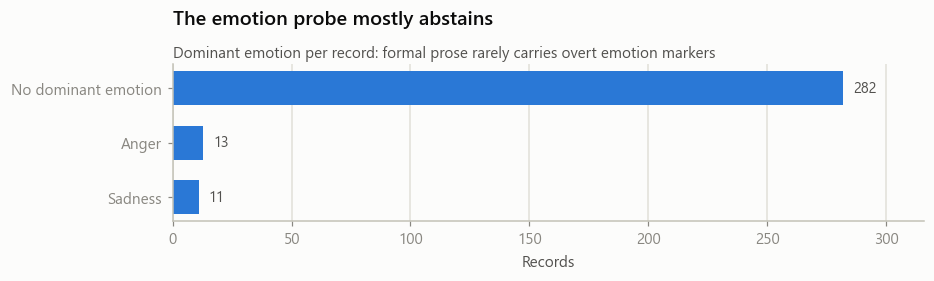

In [17]:
fig = plots.emotion_distribution(
    scored, "The emotion probe mostly abstains",
    subtitle="Dominant emotion per record: formal prose rarely carries overt emotion markers",
)
plots.save_figure(fig, "emotion_distribution", FIGURES)

This abstention is informative rather than disappointing. The model was trained on tweets, where feelings are performed with insults, exclamation marks and emoji. PQR narratives are written for a bureaucratic audience: residents describe anger inducing situations in deliberately measured language, and the classifier correctly reports that no overt emotion is displayed in 92 percent of records. Polarity, not emotion, is the robust signal in this register. The minority that does show emotion splits between anger and sadness, and it reads like it should:

In [18]:
emotional = scored[scored["emotion"] != "others"]
print(f"{len(emotional)} records show a dominant emotion "
      f"({(scored['emotion'] == 'anger').sum()} anger, {(scored['emotion'] == 'sadness').sum()} sadness)")
emotional.nlargest(4, "emotion_prob")[["description", "emotion", "emotion_prob", "sentiment"]]

24 records show a dominant emotion (13 anger, 11 sadness)


,description,emotion,emotion_prob,sentiment
208,Cliente presenta queja en contra de contratista [CONTRATISTA] ct 11900. encargada del ...,anger,0.954001,NEG
65,El día 16 de Abril se realizaron trabajos de alcantarillado y el contratista cometió u...,anger,0.929554,NEG
88,Con radicado del asunto cliente Cergio [NOMBRE] [DIRECCION] [DIRECCION] -24 (INTERIOR ...,anger,0.869479,NEG
279,Sector o barrio donde están realizando los trabajos: Las Vegas -Niquia Hace cuánto tie...,anger,0.865925,NEG


## 8. Where and when negativity concentrates

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/sentiment_by_type.png')

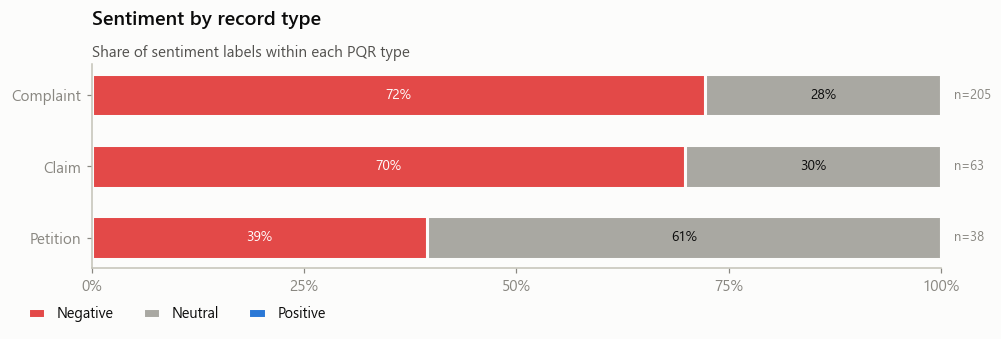

In [19]:
fig = plots.sentiment_share_by_category(
    scored, "pqr_type", "Sentiment by record type",
    subtitle="Share of sentiment labels within each PQR type",
    display=config.VALUE_DISPLAY,
)
plots.save_figure(fig, "sentiment_by_type", FIGURES)

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/sentiment_by_municipality.png')

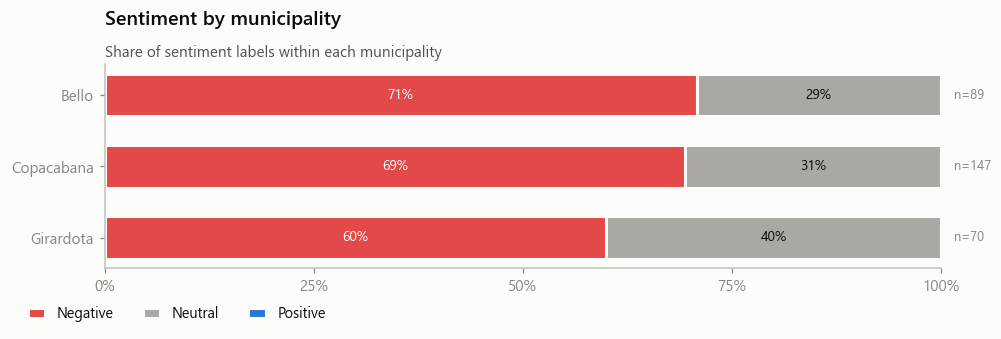

In [20]:
fig = plots.sentiment_share_by_category(
    scored, "municipality", "Sentiment by municipality",
    subtitle="Share of sentiment labels within each municipality",
)
plots.save_figure(fig, "sentiment_by_municipality", FIGURES)

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/sentiment_by_entry_route.png')

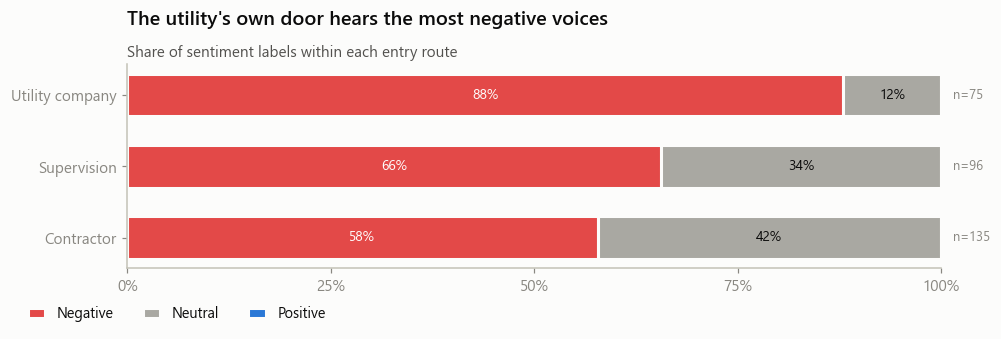

In [21]:
fig = plots.sentiment_share_by_category(
    scored, "entry_route", "The utility's own door hears the most negative voices",
    subtitle="Share of sentiment labels within each entry route",
    display=config.VALUE_DISPLAY,
)
plots.save_figure(fig, "sentiment_by_entry_route", FIGURES)

Are these differences signal or noise? The original version of this study correlated one hot dummies with probabilities, which is fragile. The standard tool is a chi square test of independence with **CramÃ©r's V** as effect size (0 means independent, 1 means fully determined).

In [22]:
rows = []
for column in ["pqr_type", "entry_route", "municipality", "watershed", "attributable"]:
    result = stats.association(scored, column, "sentiment")
    rows.append({
        "dimension": config.COLUMN_DISPLAY.get(column, column),
        "chi2": round(result.chi2, 1),
        "dof": result.dof,
        "p_value": round(result.p_value, 4),
        "cramers_v": round(result.cramers_v, 3),
    })
pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)

,dimension,chi2,dof,p_value,cramers_v
0,Entry route,20.4,2,0.0000,0.245
1,PQR type,15.9,2,0.0004,0.213
2,Attributability,6.9,2,0.0323,0.126
3,Watershed,4.3,2,0.1166,0.087
4,Municipality,2.5,2,0.2902,0.039


**Feeling follows the process, not the place.** The two strongest associations belong to entry route (V = 0.25) and record type (V = 0.21), and the two are entangled: the records that reach the utility company directly are almost pure complaints and read 88 percent negative, while the contractor's door receives nearly all petitions, the calmest record type. Geography carries almost nothing (V = 0.09 for watershed, 0.04 for municipality, both nonsignificant). Operationally that is good news: there is no "angry town" to appease, there is a works program producing similar friction wherever it digs, and a routing pattern that concentrates the sharpest records in one channel.

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/monthly_activity.png')

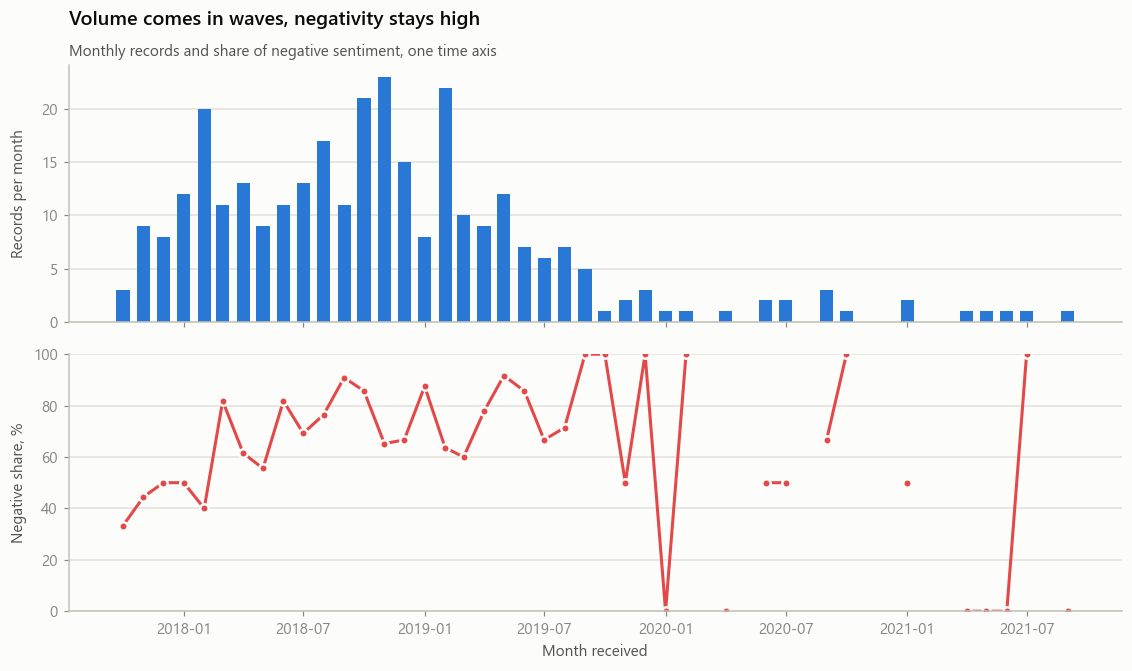

In [23]:
fig = plots.monthly_activity(
    scored, "Volume comes in waves, negativity stays high",
    subtitle="Monthly records and share of negative sentiment, one time axis",
)
plots.save_figure(fig, "monthly_activity", FIGURES)

## 9. Sentiment and operations: time to close and responsibility

Kruskal Wallis H = 0.43, p = 0.512
median days to close: {'NEG': 8.0, 'NEU': 14.0}
records per group:    {'NEG': 201, 'NEU': 97}


WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/resolution_by_sentiment.png')

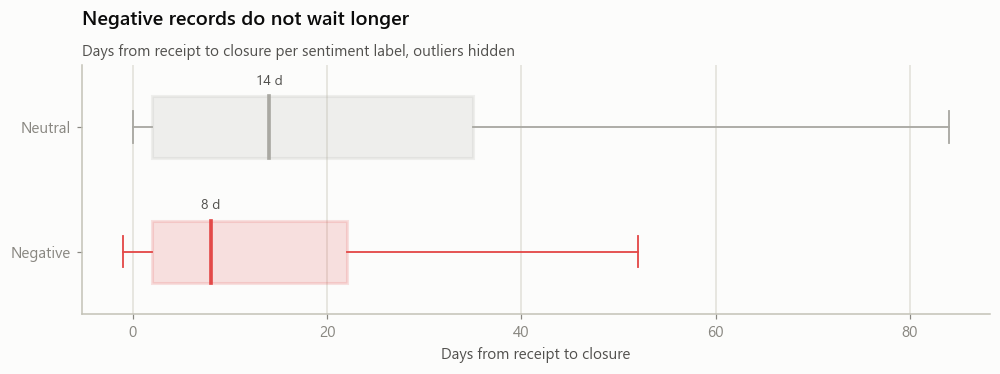

In [24]:
result = stats.kruskal_by_group(scored, "resolution_days", "sentiment")
print(f"Kruskal Wallis H = {result.statistic:.2f}, p = {result.p_value:.3f}")
print("median days to close:", result.medians.round(1).to_dict())
print("records per group:   ", result.n.to_dict())

fig = plots.resolution_by_sentiment(
    scored, "Negative records do not wait longer",
    subtitle="Days from receipt to closure per sentiment label, outliers hidden",
)
plots.save_figure(fig, "resolution_by_sentiment", FIGURES)

records closed within the regulatory deadline: 38%


WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/sentiment_by_attributability.png')

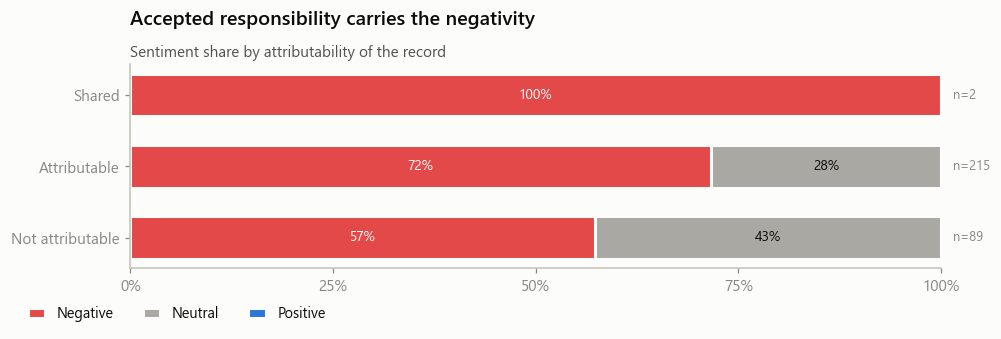

In [25]:
sla = scored.dropna(subset=["sla_met"])
print(f"records closed within the regulatory deadline: {sla['sla_met'].mean():.0%}")

fig = plots.sentiment_share_by_category(
    scored.dropna(subset=["attributable"]), "attributable", "Accepted responsibility carries the negativity",
    subtitle="Sentiment share by attributability of the record",
    display=config.VALUE_DISPLAY,
)
plots.save_figure(fig, "sentiment_by_attributability", FIGURES)

## 10. The language of each sentiment

Which words separate an angry claim from a neutral petition? Each term is scored by contrast: its mean TF IDF weight inside the class minus its mean weight everywhere else, so corpus wide construction vocabulary cancels out. Standard Spanish stopwords, the reporting boilerplate of this corpus ("usuario manifiesta que...") and the anonymization placeholders are excluded.

WindowsPath('A:/1.Automatic_Flows/9_Sentiment_Analysis_PQR/pqr_sentiment_analysis/reports/figures/distinctive_terms.png')

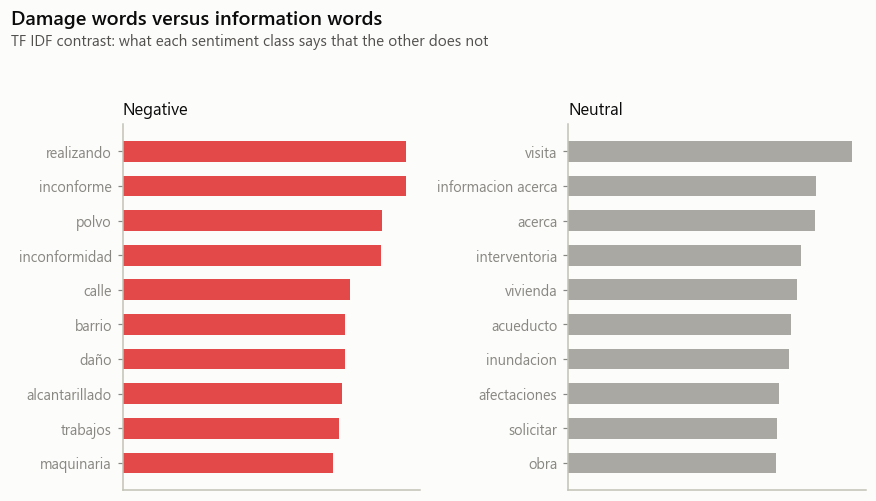

In [26]:
terms = text_mining.top_terms_by_class(scored, "description", "sentiment", top_n=10)
fig = plots.terms_panel(
    terms, "Damage words versus information words",
    subtitle="TF IDF contrast: what each sentiment class says that the other does not",
)
plots.save_figure(fig, "distinctive_terms", FIGURES)

## 11. Findings

The numbers below are computed live from the scored dataset.

In [27]:
neg_share = (scored["sentiment"] == "NEG").mean()
claims_neg = (scored.loc[scored["pqr_type"] == "claim", "sentiment"] == "NEG").mean()
petitions_neg = (scored.loc[scored["pqr_type"] == "petition", "sentiment"] == "NEG").mean()
utility_neg = (scored.loc[scored["entry_route"] == "utility_company", "sentiment"] == "NEG").mean()
abstain_share = (scored["emotion"] == "others").mean()
median_days = scored["resolution_days"].median()
sla_rate = scored["sla_met"].dropna().mean()
route_v = stats.association(scored, "entry_route", "sentiment").cramers_v
type_v = stats.association(scored, "pqr_type", "sentiment").cramers_v
geo_v = stats.association(scored, "municipality", "sentiment").cramers_v

print(f"1. {neg_share:.0%} of records are negative, none are positive.")
print(f"2. Feeling follows process, not place: entry route V {route_v:.2f} and type V {type_v:.2f}"
      f" versus municipality V {geo_v:.2f}.")
print(f"   Claims are {claims_neg:.0%} negative, petitions {petitions_neg:.0%};"
      f" the utility's direct channel reads {utility_neg:.0%} negative.")
print(f"3. Formal register hides emotion: {abstain_share:.0%} of records show no dominant emotion,"
      f" so polarity is the reliable signal in this corpus.")
print(f"4. Operations: median closure takes {median_days:.0f} days, only {sla_rate:.0%} close within"
      f" the regulatory deadline, and negative records are not deprioritized (p = 0.51).")

1. 68% of records are negative, none are positive.
2. Feeling follows process, not place: entry route V 0.25 and type V 0.21 versus municipality V 0.04.
   Claims are 70% negative, petitions 39%; the utility's direct channel reads 88% negative.
3. Formal register hides emotion: 92% of records show no dominant emotion, so polarity is the reliable signal in this corpus.
4. Operations: median closure takes 9 days, only 38% close within the regulatory deadline, and negative records are not deprioritized (p = 0.51).


**Limitations.** The corpus is one program in one region, 306 records, written during construction works: results describe this channel, not citizen sentiment in general. Robertuito is pretrained on tweets, a register close to but not identical with formal complaints, and the emotion companion abstains on most of this corpus for exactly that reason. Anonymization placeholders slightly alter some sentences, though their typed form keeps them neutral for the models. The independent cross check (kappa 0.13 against a review domain model) validates the choice of a domain matched scorer rather than the per record labels themselves: aggregate patterns are trustworthy, individual labels are not ground truth.

**Next steps.** Aspect extraction (what exactly failed: pavement, water supply, property damage), a small hand labeled sample to measure and fine tune per record accuracy on this register, and routing analytics on the utility's direct channel, which concentrates the most negative narratives.

## 12. Reproducibility

: `pip install -e .[ml]` installs the package with the transformer stack.
: First inference run downloads the three models from the Hugging Face hub, afterwards everything works offline.
: `data/pqr_scored.csv` caches model outputs, so `RUN_INFERENCE = False` (or a machine without the ML stack) reproduces every table and figure in seconds.
: Every figure in `reports/figures` is written by this notebook: delete the folder and run again to regenerate.
